# 01 · ISIC Archive — acquisition and EDA

**Project:** Skin Lesion Triage · BIU DS23 Capstone
**Owner:** Data hat · **Charter section:** 3 (Data) and the frozen de-duplication rule

## What this notebook does
1. Downloads the full ISIC metadata.
2. Builds the frozen clinical training pool by excluding PAD-UFES-20 and the unlabelled benchmark.
3. Audits labels against the frozen label policy, grouping keys, contributors and licences.
4. Saves the metadata, the resized image archive and the duplicate-exclusion list.

> **Runs on its own.** This notebook downloads the ISIC images *and* the PAD-UFES-20
> photographs it compares them against, so nothing produced by notebooks 02 or 03 is
> required. Section 6 optionally reads `data/processed/pad_split.csv` from notebook 02 to
> restrict the PAD sample to development patients; without it those cells fall back to all
> patients and label the charts accordingly.

## Target numbers (from the charter — this notebook must reproduce them)
| | |
|---|---|
| Clinical close-up images in the archive | 9,316 |
| minus PAD-UFES-20 (collection 406) | −2,298 |
| minus unlabelled benchmark images | −479 |
| **Training pool** | 6,539 images, 470 melanomas, 761 nevi |

If a number comes out different, the charter is what gets corrected — not the number.

## Outputs
| File | Contents |
|---|---|
| `data/raw/isic_clinical_metadata.csv` | all 9,316 rows, with `in_training_pool`, `exclusion_reason` and `label_family` |
| `data/raw/images/images_isic_512.tar` | the resized training images |
| `data/processed/isic_duplicate_exclusions.csv` | duplicate photographs to drop in notebook 03 |
| `reports/figures/01_*.png` | the charts |

In [1]:
# Cell 1 · Configuration (identical in every notebook)
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    PROJECT = "/content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers"
else:
    PROJECT = os.path.abspath("..")

RAW       = os.path.join(PROJECT, "data", "raw")
PROCESSED = os.path.join(PROJECT, "data", "processed")
FIGURES   = os.path.join(PROJECT, "reports", "figures")

# Where the image archive is stored. Kept as its own setting so the heavy files can later move to a
# shared folder without touching anything else. Colab addresses Drive by path, never by the id in a
# share link, so any override below must be a path under /content/drive/MyDrive/.
IMAGES_DIR = os.path.join(RAW, "images")

for d in (RAW, PROCESSED, FIGURES, IMAGES_DIR):
    os.makedirs(d, exist_ok=True)

SEED = 42              # every split in this project uses this seed
IMG_SIZE = 512         # long side, in pixels, for the training copy of the images

print("project  :", PROJECT)
print("raw      :", RAW)
print("processed:", PROCESSED)
print("images   :", IMAGES_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project  : /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers
raw      : /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/raw
processed: /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/processed
images   : /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/raw/images


In [2]:
# Cell 2 · Install the official ISIC CLI and download the complete metadata
# The metadata download is text only (a few hundred MB of CSV), not images.
!pip install -q isic-cli

META_RAW = os.path.join(RAW, "isic_metadata_full.csv")
if not os.path.exists(META_RAW):
    !isic metadata download -o "$META_RAW"
else:
    print("metadata already downloaded, skipping")

import pandas as pd
meta = pd.read_csv(META_RAW, low_memory=False)
print(f"{len(meta):,} images in the ISIC archive")
print("\ncolumns:", list(meta.columns))


metadata already downloaded, skipping
553,019 images in the ISIC archive

columns: ['isic_id', 'attribution', 'copyright_license', 'acquisition_day', 'age_approx', 'anatom_site_1', 'anatom_site_2', 'anatom_site_3', 'anatom_site_4', 'anatom_site_5', 'anatom_site_special', 'clin_size_long_diam_mm', 'concomitant_biopsy', 'dermoscopic_type', 'diagnosis_1', 'diagnosis_2', 'diagnosis_3', 'diagnosis_4', 'diagnosis_5', 'diagnosis_confirm_type', 'family_hx_mm', 'fitzpatrick_skin_type', 'image_manipulation', 'image_type', 'lesion_id', 'mel_mitotic_index', 'mel_thick_mm', 'mel_ulcer', 'melanocytic', 'patient_id', 'personal_hx_mm', 'pixels_x', 'pixels_y', 'rcm_case_id', 'sex', 'tbp_tile_type']


## 1 · Isolating the clinical close-ups

Deployment uses ordinary smartphone photographs, so the training pool is restricted to
non-dermoscopic `clinical: close-up` images to reduce domain mismatch.
`clinical: overview` images are excluded because they show a wider body region rather than a single lesion.


In [3]:
# Cell 3 · Filter to clinical close-ups, and see who contributed them
print("image_type values in the archive:")
print(meta["image_type"].value_counts(dropna=False).to_string())

clinical = meta[meta["image_type"] == "clinical: close-up"].copy()
print(f"\nclinical close-ups: {len(clinical):,}   (charter: 9,316)")

print("\ncontributors:")
print(clinical.groupby("attribution").size().sort_values(ascending=False).to_string())


image_type values in the archive:
image_type
TBP tile: close-up    401059
dermoscopic           124961
TBP tile: overview     16990
clinical: close-up      9316
clinical: overview       432
RCM: tile                151
RCM: mosaic               85
RCM: macroscopic          24
NaN                        1

clinical close-ups: 9,316   (charter: 9,316)

contributors:
attribution
MILK study team                                5719
Federal University of Espírito Santo (UFES)    2298
Memorial Sloan Kettering Cancer Center         1241
Anonymous                                        52
Hospital Italiano de Buenos Aires                 6


## 2 · Frozen de-duplication rule

PAD-UFES-20 also appears in ISIC as collection 406. Its entire ISIC copy is excluded from the ISIC
training pool so that PAD can be managed separately with a patient-level split in notebook 02.

The unlabelled benchmark collection is also excluded because it has no released target labels.
Rows are flagged rather than deleted so the decision remains auditable.

In [4]:
# Cell 4 · Apply the two exclusions as flags
is_pad = clinical["attribution"].str.contains("UFES|Esp.rito Santo", na=False, regex=True)
is_unlabelled = clinical["diagnosis_1"].isna()

clinical["exclusion_reason"] = ""
clinical.loc[is_pad, "exclusion_reason"] = "pad_test_set"
clinical.loc[~is_pad & is_unlabelled, "exclusion_reason"] = "unlabelled_benchmark"
clinical["in_training_pool"] = clinical["exclusion_reason"] == ""

pool = clinical[clinical["in_training_pool"]].copy()

print(f"clinical close-ups        : {len(clinical):,}")
print(f"  excluded, PAD test set  : {is_pad.sum():,}")
print(f"  excluded, no label      : {(~is_pad & is_unlabelled).sum():,}")
print(f"  training pool           : {len(pool):,}   (charter: 6,539)")

if len(pool) != 6539:
    print(f"\n>>> CHARTER MISMATCH: pool is {len(pool)}, charter says 6,539. "
          "Update the charter with the real number and say why it moved.")


clinical close-ups        : 9,316
  excluded, PAD test set  : 2,298
  excluded, no label      : 479
  training pool           : 6,539   (charter: 6,539)


## 3 · Labels

`diagnosis_1` provides the top-level Benign / Malignant / Indeterminate label.
The binary target is malignant vs. non-malignant.

Indeterminate cases are flagged here and excluded during preprocessing in notebook 03.


In [5]:
# Cell 5 · Binary label + melanoma flag
print("diagnosis_1:")
print(pool["diagnosis_1"].value_counts(dropna=False).to_string())

diag_cols = [c for c in ["diagnosis_2", "diagnosis_3", "diagnosis_4", "diagnosis_5"] if c in pool.columns]
diag_text = pool[diag_cols].fillna("").agg(" ".join, axis=1).str.lower()

pool["is_malignant"] = (pool["diagnosis_1"] == "Malignant").astype(int)
pool["is_indeterminate"] = (pool["diagnosis_1"] == "Indeterminate").astype(int)
pool["is_melanoma"] = diag_text.str.contains("melanoma", na=False).astype(int)

n_mel = int(pool["is_melanoma"].sum())
print(f"\nmalignant     : {int(pool['is_malignant'].sum()):,}")
print(f"indeterminate : {int(pool['is_indeterminate'].sum()):,}")
print(f"melanomas     : {n_mel:,}   (charter: 470)")
print(f"malignant share: {100*pool['is_malignant'].mean():.1f}%  "
      "(charter risk table: ~57% - biopsy-selected lesions, far above the real population rate)")

if n_mel != 470:
    print(f"\n>>> CHARTER MISMATCH: {n_mel} melanomas, charter says 470. Correct the charter.")

# How deep the ISIC diagnosis hierarchy actually goes in this pool. The spectrum itself is in cell 9b.
print("\ndiagnosis levels filled:",
      {c: f"{100*pool[c].notna().mean():.0f}%" for c in diag_cols})


diagnosis_1:
diagnosis_1
Malignant        3698
Benign           2717
Indeterminate     124

malignant     : 3,698
indeterminate : 124
melanomas     : 470   (charter: 470)
malignant share: 56.6%  (charter risk table: ~57% - biopsy-selected lesions, far above the real population rate)

diagnosis levels filled: {'diagnosis_2': '91%', 'diagnosis_3': '80%', 'diagnosis_4': '12%', 'diagnosis_5': '0%'}


In [6]:
# Cell 5b · Does diagnosis_1 == "Malignant" match the frozen label policy (MEL + BCC + SCC)?
import numpy as np

dx_all = (pool["diagnosis_3"]
          .fillna(pool["diagnosis_2"])
          .fillna("(no diagnosis_2/3)"))

family = np.select(
    [dx_all.str.contains("melanoma", case=False),
     dx_all.str.contains("basal cell", case=False),
     dx_all.str.contains("squamous|keratoacanthoma|bowen", case=False)],
    ["MEL", "BCC", "SCC"],
    default="OTHER",
)

# One label-family column for every pool row, saved with the metadata in Cell 9
pool["label_family"] = np.where(
    pool["is_malignant"] == 1, family,
    np.where(pool["is_indeterminate"] == 1, "INDETERMINATE", "BENIGN"))

mal = pool["is_malignant"] == 1
print("malignant rows by policy family:")
print(pool.loc[mal, "label_family"].value_counts().to_string())

print("\nmalignant rows OUTSIDE MEL/BCC/SCC - what they are:")
print(dx_all[mal & (pool["label_family"] == "OTHER")].value_counts().to_string())

print("\ncross-check with the melanoma flag (every MEL row should have is_melanoma = 1):")
print(pd.crosstab(pool.loc[mal, "label_family"], pool.loc[mal, "is_melanoma"]).to_string())

malignant rows by policy family:
label_family
BCC      2551
SCC       668
MEL       470
OTHER       9

malignant rows OUTSIDE MEL/BCC/SCC - what they are:
diagnosis_3
Collision - At least one malignant proliferation    9

cross-check with the melanoma flag (every MEL row should have is_melanoma = 1):
is_melanoma      0    1
label_family           
BCC           2551    0
MEL              0  470
OTHER            9    0
SCC            668    0


**Label-policy check.** All 3,698 `Malignant` rows were mapped to the frozen policy:
BCC 2,551 · SCC 668 (including 162 keratoacanthoma, which ISIC labels malignant) · MEL 470 · other 9.
The melanoma family agrees exactly with `is_melanoma` (470/470, zero conflicts).
The 9 "other" rows are all *Collision – at least one malignant proliferation*: the malignant component is not identified, so they can be neither verified as MEL/BCC/SCC nor labelled benign. They are **dropped in notebook 03**, like the 124 Indeterminate rows.

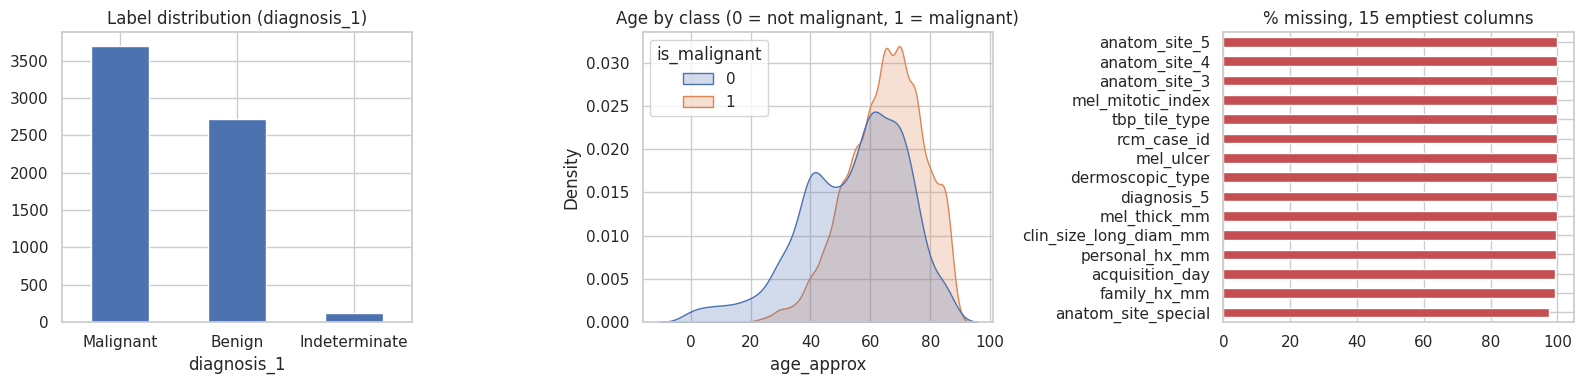

age by class:
               count  mean   std
is_malignant                    
0             2710.0  54.5  17.4
1             3698.0  65.1  12.4

key metadata fields, % filled:
  age_approx                99.9%
  sex                       99.9%
  anatom_site_1             98.6%
  patient_id                19.1%
  lesion_id                 99.2%
  fitzpatrick_skin_type     19.1%
  copyright_license        100.0%


In [7]:
# Cell 6 · Class balance, age, and what metadata actually exists
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

pool["diagnosis_1"].value_counts().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Label distribution (diagnosis_1)")
ax[0].tick_params(axis="x", rotation=0)

labelled = pool[pool["is_indeterminate"] == 0]
sns.kdeplot(data=labelled, x="age_approx", hue="is_malignant", fill=True,
            common_norm=False, ax=ax[1])
ax[1].set_title("Age by class (0 = not malignant, 1 = malignant)")

missing = pool.isna().mean().mul(100).sort_values(ascending=False).head(15)
missing.plot.barh(ax=ax[2], color="#C44E52")
ax[2].invert_yaxis()
ax[2].set_title("% missing, 15 emptiest columns")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "01_isic_overview.png"), dpi=120)
plt.show()

print("age by class:")
print(labelled.groupby("is_malignant")["age_approx"].describe()[["count", "mean", "std"]].round(1).to_string())
print("\nkey metadata fields, % filled:")
for c in ["age_approx", "sex", "anatom_site_1", "patient_id", "lesion_id",
          "fitzpatrick_skin_type", "copyright_license"]:
    if c in pool.columns:
        print(f"  {c:<24} {100*pool[c].notna().mean():5.1f}%")


## 4 · Grouping structure and leakage

Images from the same patient or lesion must remain in the same split.
The frozen rule is patient-level grouping where `patient_id` exists, otherwise lesion-level grouping.

The cell below quantifies leakage from a naive image-level split.


In [8]:
# Cell 7 · Grouping structure and a leakage demonstration
from sklearn.model_selection import train_test_split

print("coverage of the grouping keys:")
for c in ["patient_id", "lesion_id"]:
    if c in pool.columns:
        print(f"  {c:<12} filled {100*pool[c].notna().mean():5.1f}%  "
              f"| distinct values: {pool[c].nunique():,}")

print("\nper contributor:")
for src, g in pool.groupby("attribution"):
    pid = 100 * g["patient_id"].notna().mean() if "patient_id" in g else 0
    lid = 100 * g["lesion_id"].notna().mean() if "lesion_id" in g else 0
    print(f"  {src[:45]:<45} n={len(g):>5,} | patient_id {pid:5.1f}% | lesion_id {lid:5.1f}%")

if "lesion_id" in pool.columns and pool["lesion_id"].notna().any():
    d = pool.dropna(subset=["lesion_id"]).copy()
    d["lesion_key"] = d["attribution"].fillna("unknown_source").astype(str) + "::L::" + d["lesion_id"].astype(str)
    multi = (d.groupby("lesion_key").size() > 1).mean()
    tr, te = train_test_split(d, test_size=0.2, random_state=SEED)   # deliberately naive
    leaked = te["lesion_key"].isin(set(tr["lesion_key"])).mean()
    print(f"\nlesions with more than one image : {100*multi:.1f}%")
    print(f"naive split by image -> {100*leaked:.1f}% of test images have their own lesion in train")
    print("This is the number that justifies grouped splitting. It belongs in the README.")


coverage of the grouping keys:
  patient_id   filled  19.1%  | distinct values: 79
  lesion_id    filled  99.2%  | distinct values: 6,458

per contributor:
  Anonymous                                     n=   52 | patient_id   0.0% | lesion_id   0.0%
  Hospital Italiano de Buenos Aires             n=    6 | patient_id 100.0% | lesion_id 100.0%
  MILK study team                               n=5,240 | patient_id   0.0% | lesion_id 100.0%
  Memorial Sloan Kettering Cancer Center        n=1,241 | patient_id 100.0% | lesion_id 100.0%

lesions with more than one image : 0.2%
naive split by image -> 1.0% of test images have their own lesion in train
This is the number that justifies grouped splitting. It belongs in the README.


In [9]:
# Cell 8 · Licence distribution and non-NC subset

if "copyright_license" in pool.columns:
    print(pool["copyright_license"].value_counts(dropna=False).to_string())

    ok = pool["copyright_license"].isin(["CC-0", "CC-BY"])

    print(f"\nCC-0 / CC-BY subset: {ok.sum():,} of {len(pool):,}")
    print(
        f"melanomas in this subset: "
        f"{int((ok & (pool['is_melanoma'] == 1)).sum())}"
    )


copyright_license
CC-BY-NC    5240
CC-BY       1247
CC-0          52

CC-0 / CC-BY subset: 1,299 of 6,539
melanomas in this subset: 20


In [10]:
# Cell 9 · Save the metadata - the full table, with flags
dest = os.path.join(RAW, "isic_clinical_metadata.csv")

cols = [c for c in ["isic_id", "attribution", "copyright_license", "patient_id", "lesion_id",
                    "age_approx", "sex", "anatom_site_1", "anatom_site_special",
                    "fitzpatrick_skin_type", "image_type",
                    "diagnosis_1", "diagnosis_2", "diagnosis_3",
                    "exclusion_reason", "in_training_pool"] if c in clinical.columns]

out = clinical[cols].copy()
for c in ["is_malignant", "is_indeterminate", "is_melanoma", "label_family"]:
    out[c] = pool[c].reindex(out.index)          # NaN for rows outside the training pool

out.to_csv(dest, index=False)
print(f"saved {len(out):,} rows -> {dest}")
print("columns:", list(out.columns))
print("\nlabel families in the training pool:")
print(out.loc[out["in_training_pool"], "label_family"].value_counts().to_string())
print("\nAll 9,316 clinical rows are kept. Excluded ones carry a reason, so the decision is auditable.")


saved 9,316 rows -> /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/raw/isic_clinical_metadata.csv
columns: ['isic_id', 'attribution', 'copyright_license', 'patient_id', 'lesion_id', 'age_approx', 'sex', 'anatom_site_1', 'anatom_site_special', 'fitzpatrick_skin_type', 'image_type', 'diagnosis_1', 'diagnosis_2', 'diagnosis_3', 'exclusion_reason', 'in_training_pool', 'is_malignant', 'is_indeterminate', 'is_melanoma', 'label_family']

label families in the training pool:
label_family
BENIGN           2717
BCC              2551
SCC               668
MEL               470
INDETERMINATE     124
OTHER               9

All 9,316 clinical rows are kept. Excluded ones carry a reason, so the decision is auditable.


In [11]:
# Cell 9b · Audits the charter depends on
print("--- body site ---")
print(f"anatom_site_1 filled: {100*pool['anatom_site_1'].notna().mean():.1f}%")
print(pool["anatom_site_1"].value_counts(dropna=False).head(8).to_string())

print("\n--- what the 124 Indeterminate actually are ---")
ind = pool[pool["is_indeterminate"] == 1]
print(ind["diagnosis_3"].fillna(ind["diagnosis_2"]).value_counts(dropna=False).head(8).to_string())

print("\n--- nevi ---")
n_nevi = int((pool["diagnosis_3"] == "Nevus").sum())
print(f"nevi: {n_nevi:,}   (charter: 761)")

# What the looser substring search picks up on top of the category - document it, do not ignore it.
extra = pool[diag_text.str.contains("nevus", na=False) & (pool["diagnosis_3"] != "Nevus")]
print(f"rows mentioning 'nevus' but not categorised as Nevus: {len(extra)}")
if len(extra):
    print(extra["diagnosis_3"].fillna("(no diagnosis_3)").value_counts().to_string())

print("\n--- diagnosis spectrum ---")
print(pool["diagnosis_3"].value_counts(dropna=False).head(12).to_string())

print("\n--- skin tone ---")
print(pool["fitzpatrick_skin_type"].value_counts(dropna=False).to_string())

print("\n--- melanoma cross-check ---")
if "mel_thick_mm" in pool.columns:
    odd = int((pool["mel_thick_mm"].notna() & (pool["is_melanoma"] == 0)).sum())
    print(f"rows with a Breslow thickness but not flagged melanoma: {odd}  (should be 0)")
else:
    print("mel_thick_mm not in the saved columns - skipped")

assert n_nevi == 761, f"Expected 761 nevi, found {n_nevi:,}"

--- body site ---
anatom_site_1 filled: 98.6%
anatom_site_1
Trunk                2485
Head and neck        1590
Lower extremity      1322
Upper extremity      1043
NaN                    91
Anogenital region       8

--- what the 124 Indeterminate actually are ---
diagnosis_3
Solar or actinic keratosis       123
Atypical melanocytic neoplasm      1

--- nevi ---
nevi: 761   (charter: 761)
rows mentioning 'nevus' but not categorised as Nevus: 9
diagnosis_3
Mucosal melanotic macule    7
Ink-spot lentigo            2

--- diagnosis spectrum ---
diagnosis_3
Basal cell carcinoma                 2551
NaN                                  1296
Nevus                                 761
Seborrheic keratosis                  340
Squamous cell carcinoma, Invasive     311
Melanoma Invasive                     263
Melanoma in situ                      185
Squamous cell carcinoma in situ       180
Keratoacanthoma                       162
Lichen planus like keratosis          135
Solar or actinic ker

In [12]:
# Cell 9c · Could the model learn the contributor instead of the disease?
print(pd.crosstab(pool["attribution"], pool["diagnosis_1"], normalize="index").mul(100).round(1).to_string())
print("\nmelanomas per contributor:")
print(pool.groupby("attribution")["is_melanoma"].agg(["sum", "mean"]).round(3).to_string())

diagnosis_1                             Benign  Indeterminate  Malignant
attribution                                                             
Anonymous                                  0.0            0.0      100.0
Hospital Italiano de Buenos Aires          0.0            0.0      100.0
MILK study team                           28.3            2.3       69.4
Memorial Sloan Kettering Cancer Center    99.4            0.1        0.5

melanomas per contributor:
                                        sum   mean
attribution                                       
Anonymous                                12  0.231
Hospital Italiano de Buenos Aires         2  0.333
MILK study team                         450  0.086
Memorial Sloan Kettering Cancer Center    6  0.005


In [13]:
# Cell 9d · How much of the task can be solved from the contributor alone?
import numpy as np
from sklearn.model_selection import cross_val_score, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline

lab = pool[pool["is_indeterminate"] == 0].copy()

# Group at the strictest available level (identical to notebook 03, Cell 3).
# Identifier namespaces are prefixed so patient/lesion IDs
# from different contributing sources cannot collide.
source_key = lab["attribution"].fillna("unknown_source").astype(str)
patient_key = lab["patient_id"].astype(str)
lesion_key = lab["lesion_id"].astype(str)

g = np.where(
    lab["patient_id"].notna(),
    source_key + "::P::" + patient_key,
    np.where(
        lab["lesion_id"].notna(),
        source_key + "::L::" + lesion_key,
        source_key + "::I::" + lab["isic_id"].astype(str)
    )
)

sc = cross_val_score(
    make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        LogisticRegression(max_iter=1000, class_weight="balanced")
    ),
    lab[["attribution"]],
    lab["is_malignant"],
    groups=g,
    cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED),
    scoring="roc_auc"
)

print(f"contributor-only AUC: {sc.mean():.3f} +/- {sc.std():.3f}")
print("Anything the image model achieves on an ISIC-internal split must be read against this number.")

contributor-only AUC: 0.729 +/- 0.016
Anything the image model achieves on an ISIC-internal split must be read against this number.


## 5 · Images

Images are downloaded with the official ISIC CLI, resized to a maximum side of 512 px as a
compute/storage trade-off, and packed into a single archive for efficient training from Drive.
The download and resize steps are resumable.


In [14]:
# Cell 10 · Download the images (about 20-40 minutes on first run)
# Skipped when the 512-px training copies already exist on Drive: no later cell reads the
# temporary originals any more, so a re-run must not download 2.3 GB again.
LOCAL_IMG = "/content/isic_images" if IN_COLAB else os.path.join(RAW, "isic_images")
ISIC_512  = os.path.join(IMAGES_DIR, "isic_512")
TAR       = os.path.join(IMAGES_DIR, "images_isic_512.tar")

n_ready = (len([f for f in os.listdir(ISIC_512) if f.lower().endswith(".jpg")])
           if os.path.isdir(ISIC_512) else 0)
# The tar is the artefact that persists. The unpacked folder is resolved in Cell 11b, so a
# missing folder is not a reason to download 2.3 GB again.
NEED_IMAGES = not os.path.exists(TAR)

if NEED_IMAGES:
    os.makedirs(LOCAL_IMG, exist_ok=True)
    already = len([f for f in os.listdir(LOCAL_IMG) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    print(f"{already:,} image files already present in {LOCAL_IMG}")
    if already < 9000:
        # One search, the whole clinical pool. Excluded images are removed locally in the next cell.
        !isic image download --search 'image_type:"clinical: close-up"' "$LOCAL_IMG"
else:
    print(f"archive already built ({n_ready:,} images unpacked on Drive) - download skipped")

archive already built (6,539 images unpacked on Drive) - download skipped


In [15]:
# Cell 11 · Keep only the training pool, resize, and pack into one archive
from PIL import Image
import tarfile

if not NEED_IMAGES:
    print(f"archive already built: {TAR}  ({os.path.getsize(TAR)/1e9:.2f} GB) - nothing to do")
else:
    keep = set(pool["isic_id"])
    src_files = [f for f in os.listdir(LOCAL_IMG) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    print(f"{len(src_files):,} downloaded files, {len(keep):,} belong to the training pool")

    RESIZED = os.path.join(os.path.dirname(LOCAL_IMG), "isic_512")
    os.makedirs(RESIZED, exist_ok=True)

    done = skipped = failed = 0
    for f in src_files:
        isic_id = os.path.splitext(f)[0]
        if isic_id not in keep:
            skipped += 1
            continue
        dst = os.path.join(RESIZED, f"{isic_id}.jpg")
        if os.path.exists(dst):
            done += 1
            continue
        try:
            with Image.open(os.path.join(LOCAL_IMG, f)) as im:
                im = im.convert("RGB")
                im.thumbnail((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
                im.save(dst, "JPEG", quality=92)
            done += 1
        except Exception as e:
            failed += 1
            print(f"  failed {isic_id}: {e}")
    print(f"\nresized: {done:,} | not in pool: {skipped:,} | failed: {failed}")

    if not os.path.exists(TAR):
        with tarfile.open(TAR, "w") as t:
            t.add(RESIZED, arcname="isic_512")
    print(f"archive: {TAR}  ({os.path.getsize(TAR)/1e9:.2f} GB)")

archive already built: /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/raw/images/images_isic_512.tar  (0.36 GB) - nothing to do


In [16]:
# Cell 11b · Resolve the image locations, and fetch the PAD photographs
# Three things every later cell depends on, settled once and in one place:
#   IMG_DIR  - the 512-px ISIC training copies, wherever they exist in this session
#   PAD_ORIG - the PAD photographs on Drive (canonical, and what notebook 03 reads)
#   PAD_READ - the same PAD photographs on local disk (fast, and what this notebook reads)
import tarfile, shutil

IMG_EXT = (".png", ".jpg", ".jpeg")

def _count(d, ext=".jpg"):
    return len([f for f in os.listdir(d) if f.lower().endswith(ext)]) if os.path.isdir(d) else 0

# --- ISIC training copies -------------------------------------------------------------------
# Always read from local disk, never from Drive. Drive is latency-bound per file: opening 6,539
# small images one at a time takes tens of minutes in a throttled session, while one sequential
# read of the 0.36 GB archive takes under a minute. Drive keeps the archive; /content serves it.
if IN_COLAB:
    IMG_DIR = "/content/isic_512"
    if _count(IMG_DIR) < len(pool):
        if os.path.exists(TAR):
            with tarfile.open(TAR) as t:
                t.extractall(path="/content")
        elif _count(ISIC_512) >= len(pool):
            shutil.copytree(ISIC_512, IMG_DIR, dirs_exist_ok=True)   # slow, but only once
        else:
            raise FileNotFoundError(
                "no training copies and no archive on Drive - re-run Cells 10 and 11")
else:
    IMG_DIR = ISIC_512

print(f"ISIC training copies: {IMG_DIR}  ({_count(IMG_DIR):,} images)")
assert _count(IMG_DIR) >= len(pool), \
    f"only {_count(IMG_DIR)} of {len(pool)} training copies found - re-run Cells 10 and 11"

# --- PAD photographs ------------------------------------------------------------------------
# Fetched here rather than in notebook 03, so this notebook runs on its own. Same mirror, same
# repository, same patterns as notebook 03 Cell 5c: one source, or the two notebooks build a
# folder of the same name from different files and every pixel statistic drifts silently.
#
# The mirror is also the read path. Drive is latency-bound - in a throttled Colab session a
# single image can take five seconds to open, and the cells below open all 2,298 of them one at
# a time. The files are identical, so no measurement changes.
PAD_ORIG     = os.path.join(IMAGES_DIR, "pad_original")
PAD_EXPECTED = 2298                 # PAD-UFES-20, and exactly the size of ISIC collection 406
os.makedirs(PAD_ORIG, exist_ok=True)

if IN_COLAB:
    !pip install -q huggingface_hub
    from huggingface_hub import snapshot_download

    MIRROR = "/content/pad_ufes20_mirror"
    snapshot_download(repo_id="SalmaneExploring/pad-ufes-20", repo_type="dataset",
                      allow_patterns=["all_images/**"], local_dir=MIRROR)

    # The mirror splits the photographs across all_images/imgs_part_1 .. imgs_part_3, so no
    # single folder holds all 2,298. Gather them into one flat directory, because every later
    # cell addresses a photograph by its bare filename. Links rather than copies: this is 3.6 GB.
    PAD_READ = "/content/pad_read"
    os.makedirs(PAD_READ, exist_ok=True)

    staged = 0
    for root, _, here in os.walk(MIRROR):
        for f in here:
            if not f.lower().endswith(IMG_EXT):
                continue
            dst = os.path.join(PAD_READ, f)
            if os.path.exists(dst):
                continue
            src = os.path.join(root, f)
            try:
                os.symlink(src, dst)
            except OSError:
                shutil.copy2(src, dst)
            staged += 1
    print(f"PAD staged locally  : {staged:,} new entries in {PAD_READ}")

    # Drive is written only when it is incomplete, so a re-run costs nothing.
    on_drive = _count(PAD_ORIG, IMG_EXT)
    if on_drive >= PAD_EXPECTED:
        print(f"PAD on Drive        : {on_drive:,} already present")
    else:
        copied = 0
        for f in os.listdir(PAD_READ):
            if f.lower().endswith(IMG_EXT) and not os.path.exists(os.path.join(PAD_ORIG, f)):
                shutil.copy2(os.path.join(PAD_READ, f), os.path.join(PAD_ORIG, f))
                copied += 1
        print(f"PAD copied to Drive : {copied:,}")
else:
    PAD_READ = PAD_ORIG

print(f"PAD read path       : {PAD_READ}  ({_count(PAD_READ, IMG_EXT):,} images)")

# Two independent counts that must agree: the files on disk, and the images this notebook
# already excluded as ISIC collection 406 in Cell 4. Notebook 03 Cell 5e goes further and
# checks that each file is the same photograph as its ISIC counterpart.
for label, n in [("Drive copy", _count(PAD_ORIG, IMG_EXT)),
                 ("read path", _count(PAD_READ, IMG_EXT))]:
    assert n == PAD_EXPECTED, (f"{label}: {n} PAD photographs, expected {PAD_EXPECTED} "
                               f"(= the {int(is_pad.sum())} images excluded as collection 406)")
print(f"both match ISIC collection 406 ({int(is_pad.sum())}) - asserted")


ISIC training copies: /content/isic_512  (6,539 images)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2298 files:   0%|          | 0/2298 [00:00<?, ?it/s]

PAD staged locally  : 0 new entries in /content/pad_read
PAD on Drive        : 2,298 already present
PAD read path       : /content/pad_read  (2,298 images)
both match ISIC collection 406 (2298) - asserted


In [17]:
# Cell 11c -  Verification · does the attribution proxy match the collections named in the charter?
import requests, time

def collection_ids(cid):
    url, out = "https://api.isic-archive.com/api/v2/images/search/", []
    params = {"collections": str(cid), "limit": 100}
    while url:
        r = requests.get(url, params=params if "?" not in url else None, timeout=60)
        r.raise_for_status()
        d = r.json()
        out += [x["isic_id"] for x in d["results"]]
        url = d.get("next"); time.sleep(0.2)
    return set(out)

ids_406 = collection_ids(406)     # PAD-UFES-20
ids_424 = collection_ids(424)     # MILK10k Benchmark

clin_ids    = set(clinical["isic_id"])
proxy_pad   = set(clinical.loc[is_pad, "isic_id"])
proxy_bench = set(clinical.loc[~is_pad & is_unlabelled, "isic_id"])

mismatches = []
for name, proxy, truth in [("406 / PAD", proxy_pad, ids_406 & clin_ids),
                           ("424 / benchmark", proxy_bench, ids_424 & clin_ids)]:
    print(f"\n{name}")
    print(f"  proxy: {len(proxy):,} | collection: {len(truth):,}")
    print(f"  in proxy but not in collection: {len(proxy - truth)}")
    print(f"  in collection but not in proxy: {len(truth - proxy)}")
    if proxy == truth:
        print("  IDENTICAL")
    else:
        print("  >>> NOT identical")
        mismatches.append(name)

# Freeze checks. If either fires, the archive changed under us: re-examine before training anything,
# and update the numbers in CHARTER.md and docs/DATA_DECISIONS.md to match reality.
assert not mismatches, (
    f"the attribution / missing-label proxy no longer matches the official ISIC collections: "
    f"{', '.join(mismatches)}")

assert len(pool) == 6539, f"pool is {len(pool)}, charter says 6,539"
assert int(pool["is_melanoma"].sum()) == 470, f"melanomas: {int(pool['is_melanoma'].sum())}, charter says 470"

print("\nAll freeze checks passed: the pool matches the charter exactly.")


406 / PAD
  proxy: 2,298 | collection: 2,298
  in proxy but not in collection: 0
  in collection but not in proxy: 0
  IDENTICAL

424 / benchmark
  proxy: 479 | collection: 479
  in proxy but not in collection: 0
  in collection but not in proxy: 0
  IDENTICAL

All freeze checks passed: the pool matches the charter exactly.


## 6 · Domain gap — ISIC vs. phone photos

ISIC clinical close-ups are our training proxy for smartphone photos. The cells below compare them with PAD-UFES-20 phone photos using label-free geometry, pixel statistics and visual examples.

- **Geometry (Cell 12)** is read from the ISIC metadata and covers PAD's ISIC copy, all patients.
- **Pixel statistics and image grids (Cells 13–14)** use the Mendeley PAD originals from **development patients only** (frozen split, notebook 02), put through the same preprocessing as the training copies, so no image-quality decision is shaped by test photos.
- **The overlap audit (Cell 16e)** deliberately checks **all** PAD images, test patients included, because an ISIC copy of a test photo is exactly the leak it must catch.

                                        pixels_x  pixels_y    mp  aspect
group                                                                   
Anonymous                                 3008.0    2000.0  6.02    1.50
Hospital Italiano de Buenos Aires          630.0     667.5  0.43    0.96
MILK study team                            600.0     450.0  0.27    1.33
Memorial Sloan Kettering Cancer Center    3264.0    3264.0  7.99    1.33
PAD (target domain, phone)                 779.5     779.5  0.61    1.00

images per group:
group
MILK study team                           5240
PAD (target domain, phone)                2298
Memorial Sloan Kettering Cancer Center    1241
Anonymous                                   52
Hospital Italiano de Buenos Aires            6


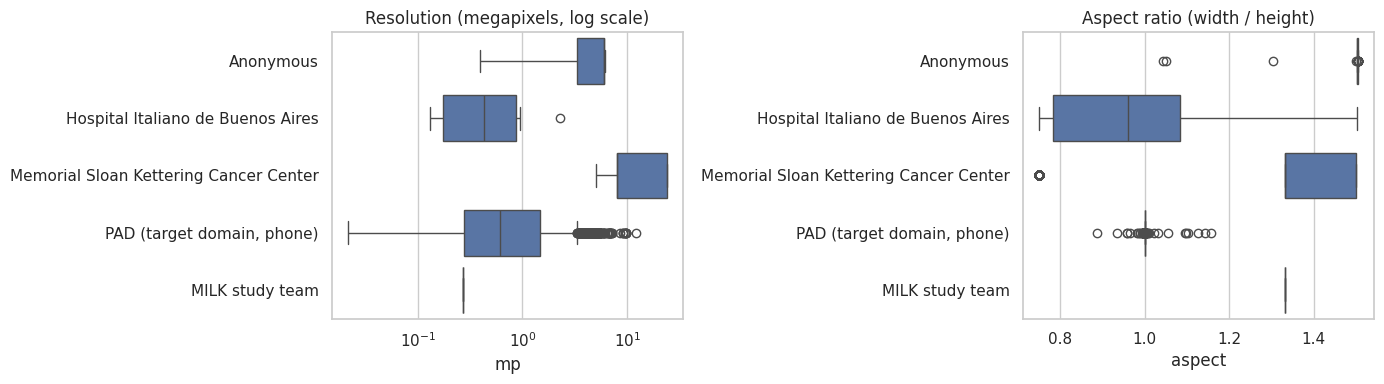

In [18]:
# Cell 12 · Image geometry per source - read from the metadata, no image loading
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

geo = clinical[clinical["image_type"] == "clinical: close-up"].copy()
geo = geo[geo["exclusion_reason"].isin(["", "pad_test_set"])]
geo["group"] = np.where(
    geo["exclusion_reason"] == "pad_test_set",
    "PAD (target domain, phone)",
    geo["attribution"]
)
geo["mp"] = geo["pixels_x"] * geo["pixels_y"] / 1e6
geo["aspect"] = geo["pixels_x"] / geo["pixels_y"]

print(geo.groupby("group")[["pixels_x", "pixels_y", "mp", "aspect"]].median().round(2).to_string())
print("\nimages per group:")
print(geo["group"].value_counts().to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=geo, y="group", x="mp", ax=ax[0]); ax[0].set_xscale("log")
ax[0].set_title("Resolution (megapixels, log scale)"); ax[0].set_ylabel("")
sns.boxplot(data=geo, y="group", x="aspect", ax=ax[1])
ax[1].set_title("Aspect ratio (width / height)"); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig(os.path.join(FIGURES, "01_geometry_by_source.png"), dpi=120); plt.show()


PAD development images available: 1,797

750 images analysed | unreadable: 0
group
ISIC · MILK                   250
ISIC · MSK                    250
PAD · phone (dev patients)    250

Median per group (all at the training resolution):
                            sharpness  brightness  contrast  saturation
group                                                                  
ISIC · MILK                     213.3       136.9      18.5       108.9
ISIC · MSK                      361.6       138.3      23.5        55.5
PAD · phone (dev patients)       83.1       145.1      22.8        78.0

Sharpness IQR per group:
                             0.25   0.75
group                                   
ISIC · MILK                 128.1  357.4
ISIC · MSK                  141.8  737.3
PAD · phone (dev patients)   30.1  233.4

Share of images whose long side is below IMG_SIZE (never upscaled):
group
ISIC · MILK                    0.0
ISIC · MSK                     0.0
PAD · phone (dev patients) 

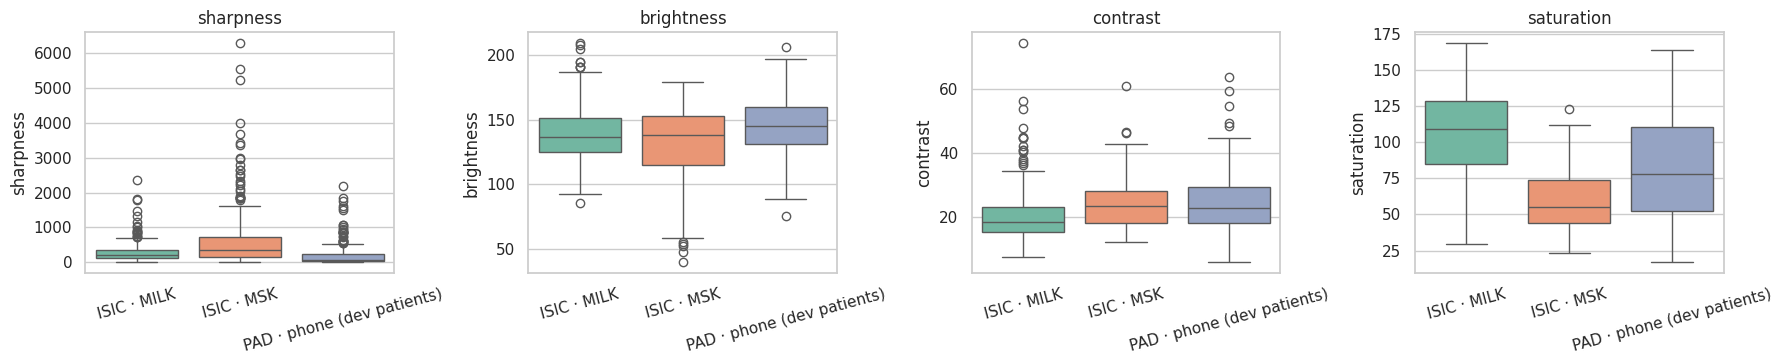

In [19]:
# Cell 13 · Domain gap — pixel statistics on the images the model will actually see
# Laplacian variance depends on resolution, so both sources go through identical
# preprocessing (RGB, long side <= IMG_SIZE, LANCZOS, JPEG q92).
# Equal-size samples per group; ISIC is split by contributor.
# PAD uses development patients (train + val) only.

import os
import io
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# IMG_DIR and PAD_READ are resolved in Cell 11b.
N_PER_GROUP = 250


def as_training_copy(path):
    """Apply the Cell 11 preprocessing in memory."""
    with Image.open(path) as im:
        im = im.convert("RGB")
        im.thumbnail((IMG_SIZE, IMG_SIZE), Image.LANCZOS)

        buf = io.BytesIO()
        im.save(buf, "JPEG", quality=92)

    return cv2.imdecode(
        np.frombuffer(buf.getvalue(), np.uint8),
        cv2.IMREAD_COLOR
    )


def stats(img, group):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    return {
        "group": group,
        "long_side": max(img.shape[:2]),
        "sharpness": cv2.Laplacian(
            gray, cv2.CV_64F
        ).var(),
        "brightness": gray.mean(),
        "contrast": gray.std(),
        "saturation": hsv[:, :, 1].mean()
    }


rows = []
unreadable = 0

# -----------------------------------------
# ISIC — training copies by contributor
# -----------------------------------------

contributor = pool["attribution"].map({
    "MILK study team": "ISIC · MILK",
    "Memorial Sloan Kettering Cancer Center": "ISIC · MSK"
})

for name in ["ISIC · MILK", "ISIC · MSK"]:

    ids = pool.loc[
        contributor == name, "isic_id"
    ]

    sampled_ids = ids.sample(
        n=min(N_PER_GROUP, len(ids)),
        random_state=SEED
    )

    for image_id in sampled_ids:

        path = os.path.join(
            IMG_DIR, f"{image_id}.jpg"
        )

        img = cv2.imread(path)

        if img is None:
            unreadable += 1
            continue

        rows.append(stats(img, name))


# -----------------------------------------
# PAD — development patients only
# -----------------------------------------

split_csv = os.path.join(
    PROCESSED, "pad_split.csv"
)

# Never fall back to the full PAD dataset
if not os.path.isfile(split_csv):
    raise FileNotFoundError(
        f"Frozen PAD split not found: {split_csv}\n"
        "Run notebook 02 first. "
        "Test patients must not be used for development EDA."
    )

pad_split = pd.read_csv(split_csv)

required_columns = {"img_id", "split"}

assert required_columns.issubset(pad_split.columns), \
    "pad_split.csv is missing required columns"

assert pad_split["split"].isin(
    ["train", "val", "test"]
).all(), "Unexpected split values in pad_split.csv"

assert pad_split["img_id"].notna().all(), \
    "Missing image identifiers in pad_split.csv"

assert pad_split["img_id"].is_unique, \
    "Duplicate image identifiers in pad_split.csv"

# Select train and validation images only
dev_imgs = set(
    pad_split.loc[
        pad_split["split"].isin(["train", "val"]),
        "img_id"
    ].astype(str)
)

# Available PAD image files
pad_files = sorted(
    f for f in os.listdir(PAD_READ)
    if f.lower().endswith(".png")
)

# Match image identifiers regardless of whether
# img_id includes the .png extension
pad_files = [
    f for f in pad_files
    if f in dev_imgs
    or os.path.splitext(f)[0] in dev_imgs
]

assert len(pad_files) > 0, (
    "No PAD development images found. "
    "Check img_id format and PAD_READ."
)

pad_group = "PAD · phone (dev patients)"

print(
    f"PAD development images available: "
    f"{len(pad_files):,}"
)

# Sample PAD development images
rng = np.random.default_rng(SEED)

sampled_files = rng.choice(
    pad_files,
    size=min(N_PER_GROUP, len(pad_files)),
    replace=False
)

for filename in sampled_files:

    path = os.path.join(
        PAD_READ, str(filename)
    )

    try:
        img = as_training_copy(path)

        if img is None:
            unreadable += 1
            continue

        rows.append(stats(img, pad_group))

    except (OSError, ValueError):
        unreadable += 1


# -----------------------------------------
# Pixel statistics summary
# -----------------------------------------

ORDER = [
    "ISIC · MILK",
    "ISIC · MSK",
    pad_group
]

px_df = pd.DataFrame(rows)

px_df["group"] = pd.Categorical(
    px_df["group"],
    categories=ORDER,
    ordered=True
)

print(
    f"\n{len(px_df):,} images analysed | "
    f"unreadable: {unreadable}"
)

print(
    px_df["group"]
    .value_counts(sort=False)
    .to_string()
)

print(
    "\nMedian per group "
    "(all at the training resolution):"
)

print(
    px_df.groupby(
        "group", observed=True
    )[
        [
            "sharpness",
            "brightness",
            "contrast",
            "saturation"
        ]
    ]
    .median()
    .round(1)
    .to_string()
)

print("\nSharpness IQR per group:")

print(
    px_df.groupby(
        "group", observed=True
    )["sharpness"]
    .quantile([0.25, 0.75])
    .unstack()
    .round(1)
    .to_string()
)

print(
    "\nShare of images whose long side "
    "is below IMG_SIZE (never upscaled):"
)

print(
    px_df.assign(
        small=px_df["long_side"] < IMG_SIZE
    )
    .groupby(
        "group", observed=True
    )["small"]
    .mean()
    .mul(100)
    .round(1)
    .to_string()
)


# -----------------------------------------
# Visual comparison
# -----------------------------------------

fig, ax = plt.subplots(
    1, 4, figsize=(18, 3.8)
)

for k, col in enumerate([
    "sharpness",
    "brightness",
    "contrast",
    "saturation"
]):

    sns.boxplot(
        data=px_df,
        x="group",
        y=col,
        hue="group",
        order=ORDER,
        hue_order=ORDER,
        legend=False,
        palette="Set2",
        ax=ax[k]
    )

    ax[k].set_title(col)
    ax[k].set_xlabel("")
    ax[k].tick_params(
        axis="x", rotation=15
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES, "01_domain_gap_pixels.png"
    ),
    dpi=120
)

plt.show()


**Interpretation (Cell 13, 250 images per group, all at 512 px).**
- **Blur is the main gap.** PAD phone photos are far less sharp than either ISIC source (median Laplacian variance 83 vs. 213 MILK and 362 MSK), and a quarter of them are smaller than 512 px. Blur is the first target for augmentation and for the image-quality check.
- **Brightness and contrast are similar** across all three groups.
- **The two ISIC contributors differ from each other as much as from PAD.** MSK images are sharper and carry half the colour saturation of MILK (55 vs. 109). Because MSK is 99.4% benign, this fingerprint survives resizing and is exactly what an image model could learn instead of the disease: the contributor-shortcut risk in the charter, now measured.
- Differences in these simple statistics establish a gap; overlap would not establish equivalence.

Any augmentation or image-quality decisions are developed using PAD train/validation patients only.

In [20]:
# Cell 14 · Look at the data
# ISIC: 512-px training copies
# PAD: original phone photos, development patients only
# Test images are never used in these visualizations.

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# IMG_DIR and PAD_READ are resolved in Cell 11b.


def isic_paths(ids):
    """Paths of available ISIC training images, in a fixed order."""
    paths = [
        os.path.join(IMG_DIR, f"{i}.jpg")
        for i in sorted(ids)
    ]
    return [p for p in paths if os.path.exists(p)]


def malignant_share(mask):
    return f"{100 * pool.loc[mask, 'is_malignant'].mean():.1f}% malignant"


def grid(rows, title, fname, per_row=5):
    """
    rows: list of (label, list_of_image_paths).
    Display a fixed-seed sample of images per row.
    """
    fig, axes = plt.subplots(
        len(rows),
        per_row,
        figsize=(3 * per_row, 3.1 * len(rows))
    )

    axes = np.atleast_2d(axes)
    rng = np.random.default_rng(SEED)

    for r, (label, paths) in enumerate(rows):

        pick = (
            rng.choice(
                paths,
                size=min(per_row, len(paths)),
                replace=False
            )
            if paths else []
        )

        for c in range(per_row):
            ax = axes[r, c]
            ax.axis("off")

            if c < len(pick):
                img = cv2.imread(str(pick[c]))

                if img is not None:
                    ax.imshow(
                        cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    )

            if c == 0:
                ax.set_title(
                    f"{label}  (n={len(paths):,})",
                    loc="left",
                    fontsize=11,
                    fontweight="bold"
                )

    plt.suptitle(
        title,
        fontsize=13,
        fontweight="bold"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(FIGURES, fname),
        dpi=120
    )

    plt.show()


# -----------------------------------------
# 1 · What the model learns from
# -----------------------------------------

# Classes follow the frozen label policy (Cell 5b)

d3 = pool["diagnosis_3"].fillna("")

grid(
    [
        (
            "Melanoma",
            isic_paths(
                pool.loc[
                    pool["label_family"] == "MEL",
                    "isic_id"
                ]
            )
        ),
        (
            "Basal cell carcinoma",
            isic_paths(
                pool.loc[
                    pool["label_family"] == "BCC",
                    "isic_id"
                ]
            )
        ),
        (
            "Squamous cell carcinoma",
            isic_paths(
                pool.loc[
                    pool["label_family"] == "SCC",
                    "isic_id"
                ]
            )
        ),
        (
            "Nevus",
            isic_paths(
                pool.loc[d3 == "Nevus", "isic_id"]
            )
        ),
        (
            "Seborrheic keratosis",
            isic_paths(
                pool.loc[
                    d3 == "Seborrheic keratosis",
                    "isic_id"
                ]
            )
        )
    ],
    "ISIC training pool - what the model learns from",
    "01_samples_by_class.png"
)


# -----------------------------------------
# 2 · The domain gap
# -----------------------------------------

# PAD visualizations use development patients only.
# No fallback to all PAD images is permitted.

split_csv = os.path.join(
    PROCESSED,
    "pad_split.csv"
)

if not os.path.isfile(split_csv):
    raise FileNotFoundError(
        f"Frozen PAD split not found: {split_csv}\n"
        "Run notebook 02 first. "
        "Test images must not appear in development visualizations."
    )

pad_split = pd.read_csv(split_csv)

# Validate split structure
required_columns = {"img_id", "split"}

assert required_columns.issubset(pad_split.columns), \
    "pad_split.csv is missing required columns"

assert pad_split["split"].isin(
    ["train", "val", "test"]
).all(), "Unexpected split values in pad_split.csv"

assert pad_split["img_id"].notna().all(), \
    "Missing image identifiers in pad_split.csv"

assert pad_split["img_id"].is_unique, \
    "Duplicate image identifiers in pad_split.csv"

# Normalize identifiers for matching PNG filenames
def normalize_img_id(value):
    name = str(value).strip().lower()
    return (
        name[:-4]
        if name.endswith(".png")
        else name
    )

dev_imgs = set(
    pad_split.loc[
        pad_split["split"].isin(["train", "val"]),
        "img_id"
    ].map(normalize_img_id)
)

test_imgs = set(
    pad_split.loc[
        pad_split["split"] == "test",
        "img_id"
    ].map(normalize_img_id)
)

assert dev_imgs.isdisjoint(test_imgs), \
    "Train/Validation and Test image IDs overlap"

# Locate available PAD photographs
pad_files = sorted(
    f for f in os.listdir(PAD_READ)
    if f.lower().endswith(".png")
)

# Select development images only
pad_files = [
    f for f in pad_files
    if normalize_img_id(f) in dev_imgs
]

assert len(pad_files) > 0, (
    "No PAD development images found. "
    "Check img_id format and PAD_READ."
)

# Explicit safeguard against Test images
assert all(
    normalize_img_id(f) not in test_imgs
    for f in pad_files
), "Test images detected in PAD visualization set"

pad_label = "PAD · phone photos (development patients)"

pad_paths = [
    os.path.join(PAD_READ, f)
    for f in pad_files
]

print(
    f"PAD development images available: "
    f"{len(pad_paths):,}"
)

print("Test images included: 0")


# -----------------------------------------
# 3 · Visualize the domain gap
# -----------------------------------------

# ISIC split by contributor because MSK is almost all benign

is_milk = (
    pool["attribution"] == "MILK study team"
)

is_msk = (
    pool["attribution"] ==
    "Memorial Sloan Kettering Cancer Center"
)

grid(
    [
        (
            f"ISIC · MILK ({malignant_share(is_milk)})",
            isic_paths(
                pool.loc[is_milk, "isic_id"]
            )
        ),
        (
            f"ISIC · MSK ({malignant_share(is_msk)})",
            isic_paths(
                pool.loc[is_msk, "isic_id"]
            )
        ),
        (
            pad_label,
            pad_paths
        )
    ],
    "The domain gap, seen",
    "01_domain_gap_visual.png"
)


Output hidden; open in https://colab.research.google.com to view.

**Visual check.** The grids reveal artefacts that summary statistics may miss, such as rulers, fingers, bandages and off-centre lesions. The image-quality rubric is developed later using the frozen PAD development split.




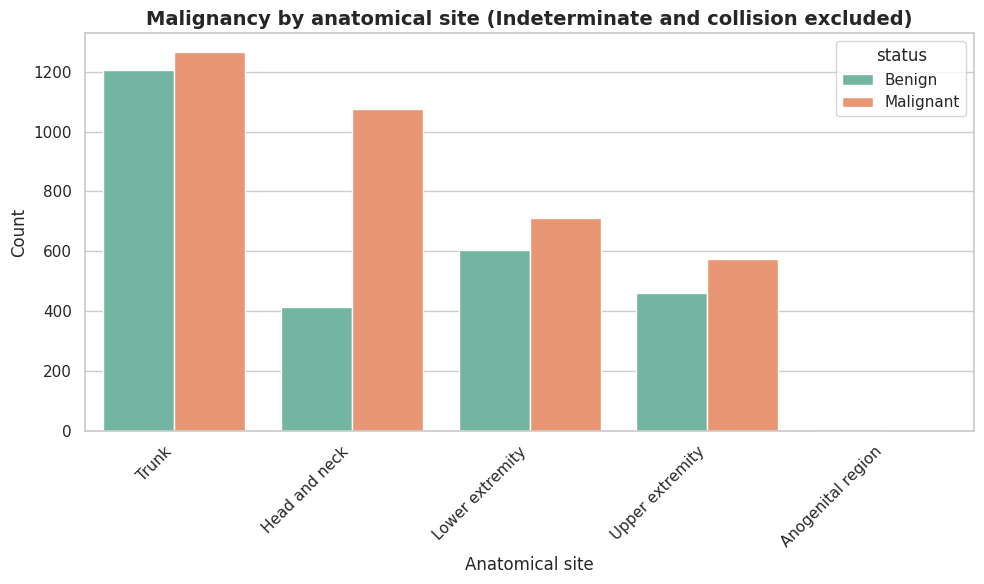

malignant share per site:
                      n  malignant_pct
anatom_site_1                         
Trunk              2471           51.2
Head and neck      1490           72.3
Lower extremity    1313           54.1
Upper extremity    1033           55.6
Anogenital region     8           25.0


In [21]:
# Cell 15 · Anatomical site vs. malignancy (Indeterminate and collision rows excluded, as in 03)
lab_site = pool[pool["label_family"].isin(["MEL", "BCC", "SCC", "BENIGN"])].copy()
lab_site["status"] = np.where(lab_site["is_malignant"] == 1, "Malignant", "Benign")
order = lab_site["anatom_site_1"].value_counts().index

fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=lab_site, x="anatom_site_1", hue="status",
              hue_order=["Benign", "Malignant"], order=order, palette="Set2", ax=ax)
ax.set_title("Malignancy by anatomical site (Indeterminate and collision excluded)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Anatomical site"); ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "anatomical_site_malignancy_analysis.png"), dpi=120)
plt.show()

print("malignant share per site:")
print(lab_site.groupby("anatom_site_1")["is_malignant"]
              .agg(n="size", malignant_pct="mean")
              .assign(malignant_pct=lambda t: (100 * t["malignant_pct"]).round(1))
              .sort_values("n", ascending=False).to_string())

image directory: /content/isic_512
scanned 6,539 | missing 0
MD5-identical groups: 2
   ['ISIC_1599277', 'ISIC_3846189']
   ['ISIC_0185358', 'ISIC_4303795']


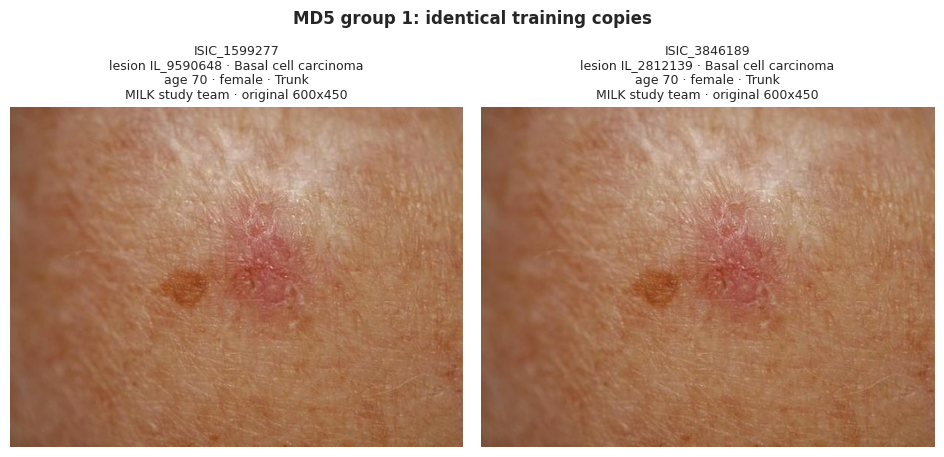

               lesion_id patient_id      attribution  age_approx     sex anatom_site_1           diagnosis_3  pixels_x  pixels_y
isic_id                                                                                                                         
ISIC_1599277  IL_9590648        NaN  MILK study team        70.0  female         Trunk  Basal cell carcinoma       600       450
ISIC_3846189  IL_2812139        NaN  MILK study team        70.0  female         Trunk  Basal cell carcinoma       600       450



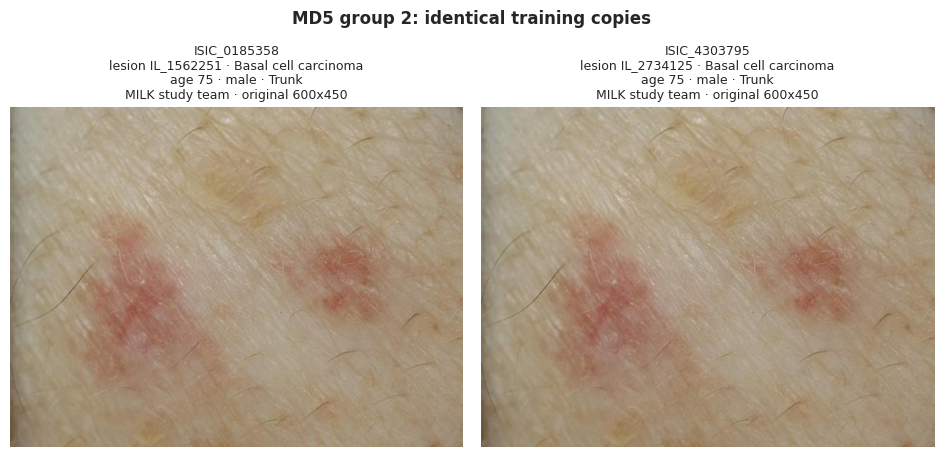

               lesion_id patient_id      attribution  age_approx   sex anatom_site_1           diagnosis_3  pixels_x  pixels_y
isic_id                                                                                                                       
ISIC_0185358  IL_1562251        NaN  MILK study team        75.0  male         Trunk  Basal cell carcinoma       600       450
ISIC_4303795  IL_2734125        NaN  MILK study team        75.0  male         Trunk  Basal cell carcinoma       600       450



In [22]:
# Cell 16 · Exact (MD5) duplicate check on the 6,539 training copies (read-only)
import hashlib
from collections import defaultdict
from PIL import Image
import matplotlib.pyplot as plt

# Resolved once in Cell 11b. Two mechanisms hunting for the same folder is exactly how two
# cells end up measuring two different copies of the same dataset without anything failing.
image_dir = IMG_DIR
print("image directory:", image_dir)


def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


hash_to_ids, missing = defaultdict(list), []
for isic_id in pool["isic_id"]:
    p = os.path.join(image_dir, f"{isic_id}.jpg")
    if os.path.exists(p):
        hash_to_ids[md5(p)].append(isic_id)
    else:
        missing.append(isic_id)

assert not missing, f"{len(missing)} training copies are missing from {image_dir}"

md5_duplicates = [sorted(ids) for ids in hash_to_ids.values() if len(ids) > 1]
print(f"scanned {len(pool) - len(missing):,} | missing {len(missing)}")
print(f"MD5-identical groups: {len(md5_duplicates)}")
for ids in md5_duplicates:
    print("  ", ids)


# Visual check: show every MD5 group side by side, with the metadata of each image,
# to see whether it is the same patient filed twice or one photo reused for two records.
info = clinical.set_index("isic_id")

def fmt(v, as_int=False):
    if pd.isna(v):
        return "?"
    return f"{int(v)}" if as_int else str(v)

for n, ids in enumerate(md5_duplicates, 1):
    fig, axes = plt.subplots(1, len(ids), figsize=(4.8 * len(ids), 5.2))
    for ax, i in zip(np.atleast_1d(axes), ids):
        with Image.open(os.path.join(image_dir, f"{i}.jpg")) as im:
            ax.imshow(im.copy())
        r = info.loc[i]
        ax.set_title(
            f"{i}\n"
            f"lesion {fmt(r['lesion_id'])} · {fmt(r['diagnosis_3'])}\n"
            f"age {fmt(r['age_approx'], True)} · {fmt(r['sex'])} · {fmt(r['anatom_site_1'])}\n"
            f"{fmt(r['attribution'])[:24]} · original {fmt(r['pixels_x'], True)}x{fmt(r['pixels_y'], True)}",
            fontsize=9)
        ax.axis("off")
    plt.suptitle(f"MD5 group {n}: identical training copies", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

    print(info.loc[ids, ["lesion_id", "patient_id", "attribution", "age_approx", "sex",
                         "anatom_site_1", "diagnosis_3", "pixels_x", "pixels_y"]].to_string())
    print()

100%|██████████| 6539/6539 [00:31<00:00, 209.30it/s]


hashed 6,539 images in 31s | missing 0

pairs within distance 3: 9 | groups: 4
--- Group 1: ['ISIC_0185358', 'ISIC_4303795']


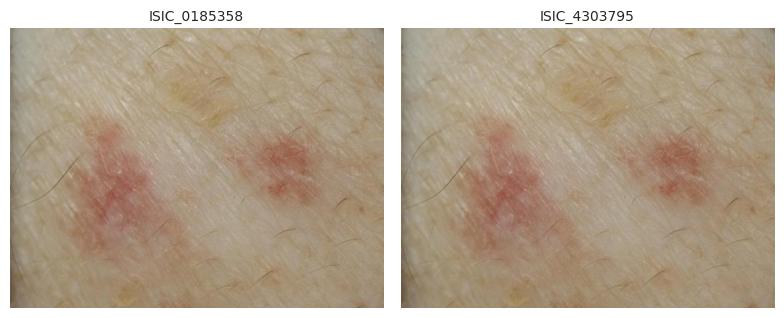

--- Group 2: ['ISIC_0443245', 'ISIC_2668215', 'ISIC_3932303', 'ISIC_6027594', 'ISIC_9209191']


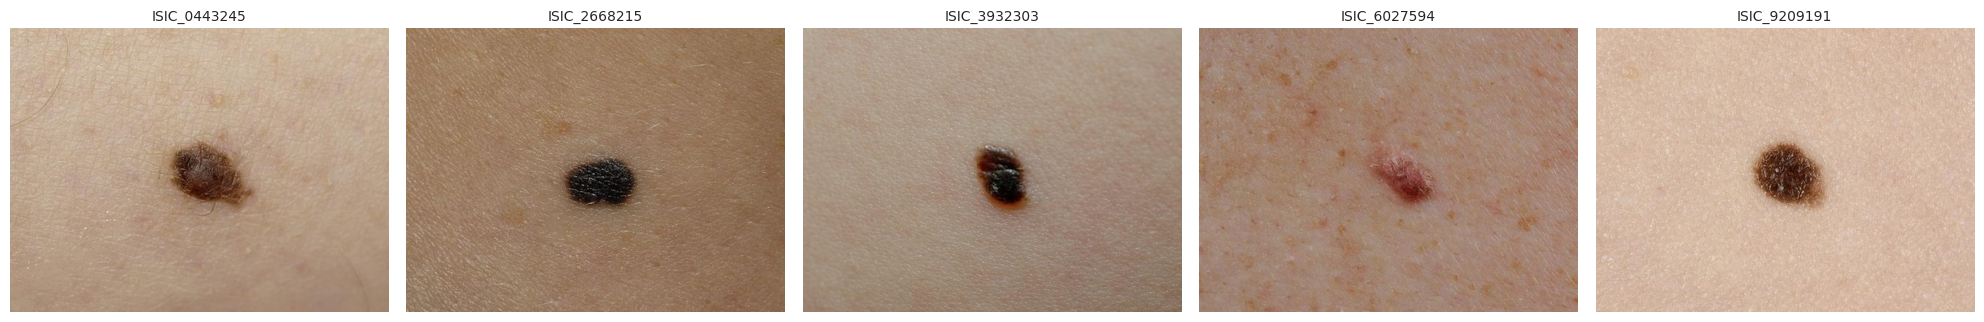

--- Group 3: ['ISIC_0572831', 'ISIC_0746280', 'ISIC_4065256', 'ISIC_8596125']


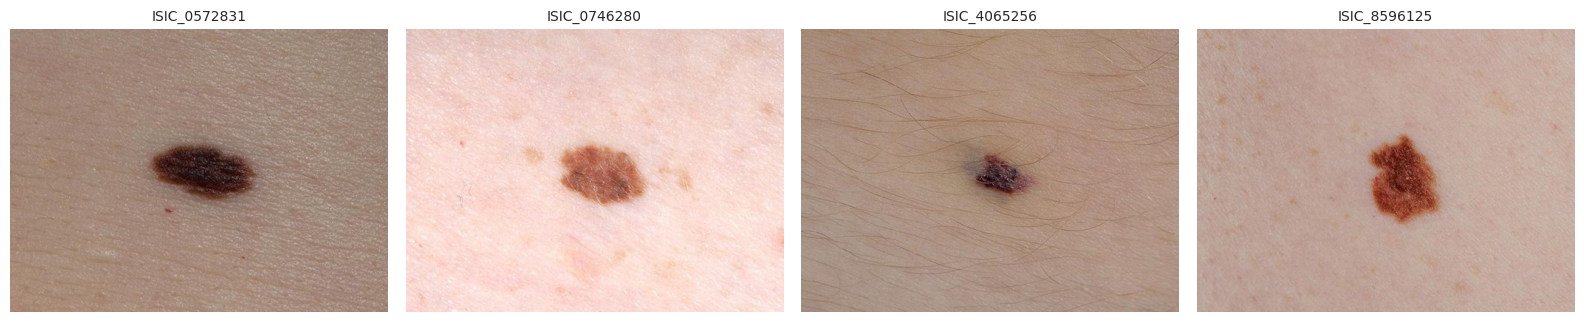

--- Group 4: ['ISIC_1599277', 'ISIC_3846189']


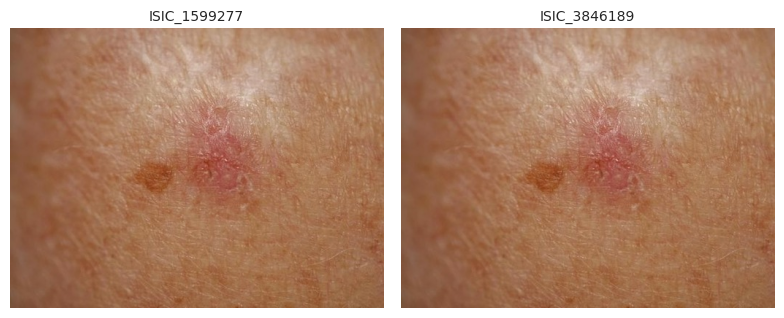

In [23]:
# Cell 16b · Perceptual-hash (pHash) near-duplicates — all pairs, transitive groups (read-only)
import sys, subprocess, time
from collections import defaultdict
from PIL import Image
from tqdm import tqdm
try:
    import imagehash
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imagehash"])
    import imagehash

# 1 · Hash every training copy (image_dir comes from Cell 16)
image_hashes, missing_files = [], []
t0 = time.time()
for isic_id in tqdm(pool["isic_id"], total=len(pool)):
    p = os.path.join(image_dir, f"{isic_id}.jpg")
    if not os.path.exists(p):
        missing_files.append(isic_id)
        continue
    with Image.open(p) as im:
        image_hashes.append((isic_id, imagehash.phash(im)))
print(f"hashed {len(image_hashes):,} images in {time.time() - t0:.0f}s | missing {len(missing_files)}")

# 2 · All-pairs Hamming distance, vectorised in blocks of 1,000 rows
THRESHOLD = 3
ids = [i for i, _ in image_hashes]
bits = np.unpackbits(
    np.array([np.frombuffer(bytes.fromhex(str(h)), dtype=np.uint8) for _, h in image_hashes]),
    axis=1).astype(np.float32)                                  # n x 64

pairs = []
for s in range(0, len(bits), 1000):
    blk = bits[s:s + 1000]
    dist = blk @ (1 - bits).T + (1 - blk) @ bits.T              # Hamming distance
    r, c = np.where(dist <= THRESHOLD)
    for a, b in zip(r + s, c):
        if a < b:
            pairs.append((ids[a], ids[b], int(dist[a - s, b])))

# 3 · Transitive groups (union-find over every pair found)
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

for a, b, _ in pairs:
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

groups = defaultdict(set)
for a, b, _ in pairs:
    groups[find(a)].update([a, b])
visual_duplicates = sorted(sorted(g) for g in groups.values())

print(f"\npairs within distance {THRESHOLD}: {len(pairs)} | groups: {len(visual_duplicates)}")

# 4 · Show every group side by side for visual inspection
for n, group in enumerate(visual_duplicates, 1):
    print(f"--- Group {n}: {group}")
    fig, axes = plt.subplots(1, len(group), figsize=(4 * len(group), 4))
    for ax, img_id in zip(np.atleast_1d(axes), group):
        with Image.open(os.path.join(image_dir, f"{img_id}.jpg")) as im:
            ax.imshow(im.copy())
        ax.set_title(img_id, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [24]:
# Cell 16c · Evidence behind every flagged group: full distance matrix, lesion_id and diagnosis
# Cell 16b already groups all pairs transitively; this cell lays out the distances and labels
# so the verdicts recorded in 16d can be checked by a reader.
import itertools

lesion_of = pool.set_index("isic_id")["lesion_id"].to_dict()
label_of  = pool.set_index("isic_id")["diagnosis_1"].to_dict()
dx_of     = pool.set_index("isic_id")["diagnosis_3"].fillna("(no diagnosis_3)").to_dict()

flagged = [i for grp in visual_duplicates for i in grp]
H = dict(image_hashes)

print(f"{len(flagged)} flagged images\n")
print("pairwise pHash Hamming distance (0 = identical hash, 64 = opposite):")
print("              " + " ".join(f"{i[-4:]:>5}" for i in flagged))
for a in flagged:
    print(f"  {a:>12} " + " ".join(f"{H[a] - H[b]:>5}" for b in flagged))

THRESHOLD = 3
parent = {i: i for i in flagged}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

for a, b in itertools.combinations(flagged, 2):
    if H[a] - H[b] <= THRESHOLD:
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

groups_by_root = {}
for i in flagged:
    groups_by_root.setdefault(find(i), []).append(i)

clusters = sorted(sorted(v) for v in groups_by_root.values())

print(f"\ntransitive clusters at threshold {THRESHOLD}: {len(clusters)}")
for n, ids in enumerate(clusters, 1):
    lesions = {lesion_of.get(i) for i in ids}
    labels  = {label_of.get(i) for i in ids}
    inner   = [H[a] - H[b] for a, b in itertools.combinations(ids, 2)]
    print(f"\n  cluster {n}: {len(ids)} images, "
          f"{len(lesions)} distinct lesion_id, {len(labels)} distinct label, "
          f"internal distance {min(inner)}-{max(inner)}")
    for i in ids:
        print(f"      {i}  lesion={lesion_of.get(i)}  {label_of.get(i)} / {dx_of.get(i)}")

13 flagged images

pairwise pHash Hamming distance (0 = identical hash, 64 = opposite):
               5358  3795  3245  8215  2303  7594  9191  2831  6280  5256  6125  9277  6189
  ISIC_0185358     0     0    34    36    36    38    34    34    36    36    36    32    32
  ISIC_4303795     0     0    34    36    36    38    34    34    36    36    36    32    32
  ISIC_0443245    34    34     0     6     4     6     2     8     6     6     6    32    32
  ISIC_2668215    36    36     6     0     2     2     4     8     6     6     6    30    30
  ISIC_3932303    36    36     4     2     0     4     2     6     4     4     4    30    30
  ISIC_6027594    38    38     6     2     4     0     6     8     6     6     6    30    30
  ISIC_9209191    34    34     2     4     2     6     0     6     4     4     4    30    30
  ISIC_0572831    34    34     8     8     6     8     6     0     4     2     4    26    26
  ISIC_0746280    36    36     6     6     4     6     4     4     0     2  

In [25]:
# Cell 16d · Record the verdicts and write the exclusion list for notebook 03
#   "duplicate" = the same photograph filed under more than one ISIC id
#   "distinct"  = inspected visually: different photographs that a perceptual hash cannot separate
# Verdicts are keyed by the image ids themselves, so a changed clustering cannot silently
# apply a verdict to the wrong group.
VERDICTS = {
    # Same photo, same patient filed twice by MILK: identical age/sex/site/size, MD5-identical
    frozenset({"ISIC_0185358", "ISIC_4303795"}): "duplicate",   # male 75, trunk, BCC, 600x450
    frozenset({"ISIC_1599277", "ISIC_3846189"}): "duplicate",   # female 70, trunk, BCC, 600x450

    # Low-detail images with near-degenerate hashes: min distance 2 (never 0),
    # contradictory diagnoses inside each group, visually different lesions
    frozenset({"ISIC_0443245", "ISIC_2668215", "ISIC_3932303",
               "ISIC_6027594", "ISIC_9209191"}): "distinct",    # 4 nevi + 1 BCC
    frozenset({"ISIC_0572831", "ISIC_0746280",
               "ISIC_4065256", "ISIC_8596125"}): "distinct",    # melanoma, hemangioma, 2 nevi
}

found = {frozenset(c) for c in clusters}
assert found == set(VERDICTS), (
    "The clusters differ from the recorded verdicts - inspect the new groups visually "
    f"and update VERDICTS.\nnew: {[sorted(x) for x in found - set(VERDICTS)]}"
    f"\ngone: {[sorted(x) for x in set(VERDICTS) - found]}")

# Evidence for every verdict: a different lesion_id is NOT proof of a different photo
# (the true duplicates also carry two lesion_ids), so show who each image belongs to.
meta = clinical.set_index("isic_id")
for n, ids in enumerate(clusters, 1):
    print(f"cluster {n} -> {VERDICTS[frozenset(ids)].upper()}")
    print(meta.loc[ids, ["lesion_id", "age_approx", "sex", "anatom_site_1",
                         "diagnosis_3", "pixels_x", "pixels_y"]].to_string())
    print()

rows = []
for n, ids in enumerate(clusters, 1):
    if VERDICTS[frozenset(ids)] != "duplicate":
        continue
    keep, extras = ids[0], ids[1:]                 # lowest isic_id is kept, deterministically
    for i in extras:
        rows.append({"isic_id": i, "reason": "near_duplicate_phash", "cluster": n,
                     "kept_instead": keep, "lesion_id": lesion_of.get(i), "label": label_of.get(i)})

dup = pd.DataFrame(rows, columns=["isic_id", "reason", "cluster", "kept_instead",
                                  "lesion_id", "label"])
dup_path = os.path.join(PROCESSED, "isic_duplicate_exclusions.csv")
dup.to_csv(dup_path, index=False)

md5_sets = {frozenset(g) for g in md5_duplicates}
dup_clusters = [c for c in clusters if VERDICTS[frozenset(c)] == "duplicate"]
print(f"clusters judged duplicate : {len(dup_clusters)}")
print(f"images to exclude         : {len(dup)}")
print()
print(dup.to_string(index=False))
print(f"\nsaved -> {dup_path}")
print(f"\nduplicate pairs also MD5-identical after our resize: "
      f"{sum(frozenset(c) in md5_sets for c in dup_clusters)} of {len(dup_clusters)}")
print("Each pair carries two different lesion_ids, so lesion-grouped splitting alone would not")
print("have kept them together. They are dropped in notebook 03; the pool here stays at 6,539.")

cluster 1 -> DUPLICATE
               lesion_id  age_approx   sex anatom_site_1           diagnosis_3  pixels_x  pixels_y
isic_id                                                                                           
ISIC_0185358  IL_1562251        75.0  male         Trunk  Basal cell carcinoma       600       450
ISIC_4303795  IL_2734125        75.0  male         Trunk  Basal cell carcinoma       600       450

cluster 2 -> DISTINCT
               lesion_id  age_approx     sex    anatom_site_1           diagnosis_3  pixels_x  pixels_y
isic_id                                                                                                
ISIC_0443245  IL_2951837        35.0    male  Lower extremity                 Nevus       600       450
ISIC_2668215  IL_4220854        40.0  female            Trunk                 Nevus       600       450
ISIC_3932303  IL_3392979        10.0    male            Trunk                 Nevus       600       450
ISIC_6027594  IL_5037876        40.0  

**Duplicate verdicts (pHash, all pairs, distance ≤ 3): 4 groups, 13 images.**
- **2 duplicate pairs:** ISIC_0185358 / ISIC_4303795 (male 75, trunk, BCC) and ISIC_1599277 / ISIC_3846189 (female 70, trunk, BCC). In each pair, age, sex, site, diagnosis and size are identical, and the 512-px copies are MD5-identical: the same MILK photograph filed under two `lesion_id`s. The higher id of each pair is dropped in notebook 03.
- **2 distinct groups** (5 and 4 images): every pair differs in age and/or sex, so no pair can be the same patient; diagnoses are mixed (nevi with a BCC; nevi with a melanoma and a hemangioma); minimum hash distance is 2, never 0. All 13 are 600×450 MILK images, whose low detail makes the perceptual hash nearly degenerate.
- A different `lesion_id` is not evidence of a different photo: both true duplicates carry two.
- The previous greedy grouping had missed 3 of these 13 images; the all-pairs search found them.

In [26]:
# Cell 16e · Does any ISIC training image also appear in PAD? (read-only)
# Unlike Cells 13-14, ALL PAD images are checked here, test patients included:
# this is a leakage check, and an ISIC copy of a PAD test photo is exactly what it must catch.
pool_dir = image_dir                                   # the 512-px training copies (Cell 16)
pad_dir  = PAD_READ                                    # local copy, Cell 11b
THRESHOLD = 3

pad_files_all = sorted(f for f in os.listdir(pad_dir) if f.lower().endswith(".png"))
pad_hashes = []
for f in tqdm(pad_files_all, desc="hashing PAD", unit="img"):   # local reads: a couple of minutes
    with Image.open(os.path.join(pad_dir, f)) as im:
        pad_hashes.append((f, imagehash.phash(im)))

def to_bits(hashes):
    return np.unpackbits(
        np.array([np.frombuffer(bytes.fromhex(str(h)), dtype=np.uint8) for _, h in hashes]),
        axis=1).astype(np.float32)

P, B = to_bits(pad_hashes), to_bits(image_hashes)      # ISIC hashes reused from Cell 16b
dist = P @ (1 - B).T + (1 - P) @ B.T                   # 2,298 x 6,539 Hamming distances
r, c = np.where(dist <= THRESHOLD)

phash_results = pd.DataFrame({
    "pad_image": [pad_hashes[i][0] for i in r],
    "pool_image": [f"{image_hashes[j][0]}.jpg" for j in c],
    "hamming_distance": dist[r, c].astype(int),
}).sort_values(["hamming_distance", "pad_image"]).reset_index(drop=True)

print(f"PAD images: {len(pad_hashes):,} | ISIC images: {len(image_hashes):,}")
print(f"candidate pairs within distance {THRESHOLD}: {len(phash_results)}")
display(phash_results)

hashing PAD: 100%|██████████| 2298/2298 [02:31<00:00, 15.12img/s]


PAD images: 2,298 | ISIC images: 6,539
candidate pairs within distance 3: 5


,pad_image,pool_image,hamming_distance
0,PAT_1415_1437_527.png,ISIC_5511326.jpg,2
1,PAT_1733_3239_934.png,ISIC_0746280.jpg,2
2,PAT_1733_3239_934.png,ISIC_3932303.jpg,2
3,PAT_1733_3239_934.png,ISIC_9209191.jpg,2
4,PAT_1733_3239_934.png,ISIC_4065256.jpg,2


Displaying top matches (out of 5 total found):


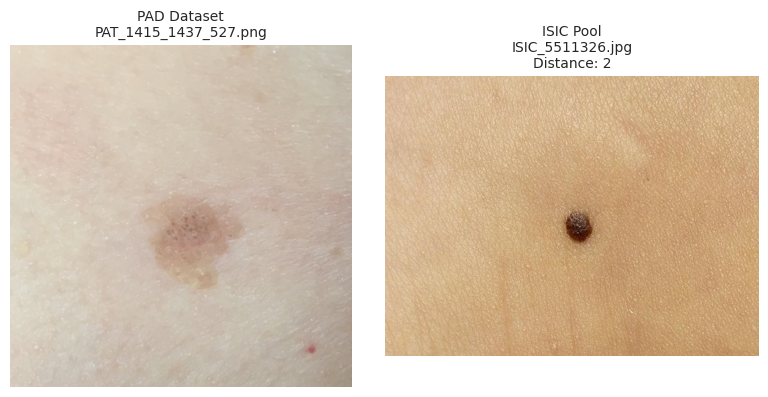

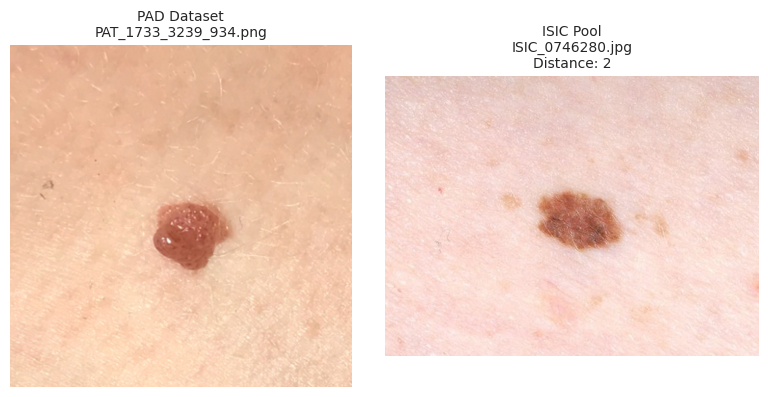

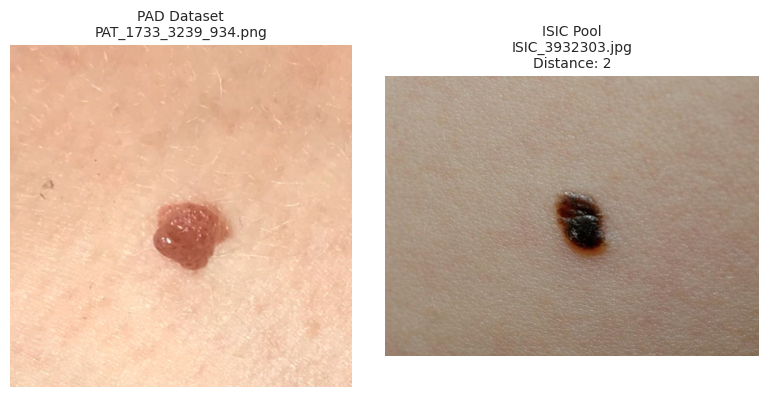

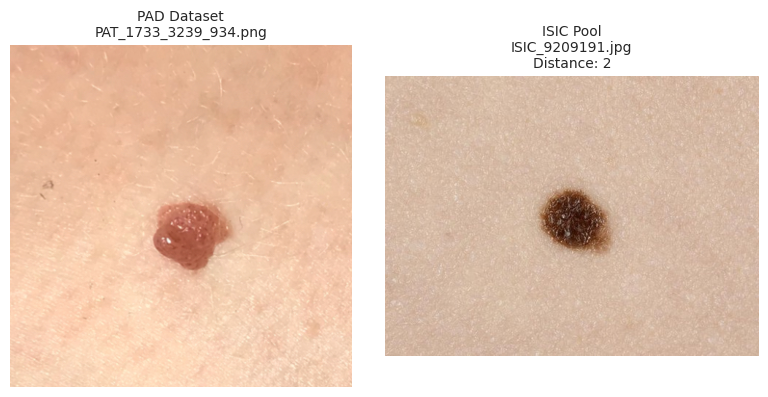

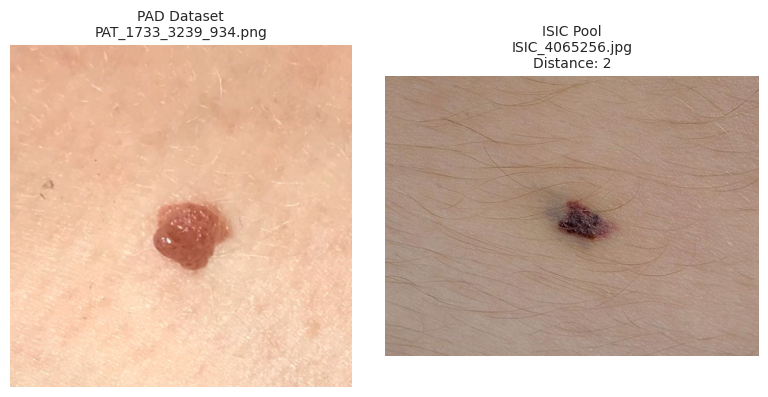

In [27]:
# Cell 16f · Every ISIC-PAD candidate side by side, for the verdict in the markdown below
import matplotlib.pyplot as plt
from PIL import Image
import os

# Ensure phash_results exists and contains data
if 'phash_results' in locals() and len(phash_results) > 0:
    print(f"Displaying top matches (out of {len(phash_results)} total found):")

    # Iterate through the results (e.g., up to the first 10 pairs)
    num_to_show = min(len(phash_results), 10)

    for idx in range(num_to_show):
        row = phash_results.iloc[idx]
        pad_img_name = row['pad_image']
        pool_img_name = row['pool_image']
        distance = row.get('hamming_distance', 'N/A')

        # Construct full paths to the image files
        pad_path = os.path.join(pad_dir, pad_img_name)
        pool_path = os.path.join(pool_dir, pool_img_name)

        # Open and display the images side by side
        fig, axes = plt.subplots(1, 2, figsize=(8, 4))

        try:
            img_pad = Image.open(pad_path)
            axes[0].imshow(img_pad)
            axes[0].set_title(f"PAD Dataset\n{pad_img_name}", fontsize=10)
            axes[0].axis('off')
        except Exception as e:
            axes[0].text(0.5, 0.5, f"Could not load PAD image:\n{e}", ha='center', va='center')
            axes[0].axis('off')

        try:
            img_pool = Image.open(pool_path)
            axes[1].imshow(img_pool)
            axes[1].set_title(f"ISIC Pool\n{pool_img_name}\nDistance: {distance}", fontsize=10)
            axes[1].axis('off')
        except Exception as e:
            axes[1].text(0.5, 0.5, f"Could not load ISIC image:\n{e}", ha='center', va='center')
            axes[1].axis('off')

        plt.tight_layout()
        plt.show()
else:
    print("No phash_results DataFrame found or it is empty. Please run the audit cell first.")

**ISIC ↔ PAD overlap (pHash ≤ 3, all PAD patients including test), inspected pair by pair.** 5 candidate pairs, all at distance 2:
- **PAT_1733_3239_934 ↔ ISIC_0746280, ISIC_4065256, ISIC_3932303, ISIC_9209191:** one PAD photo "matches" four ISIC images of four different people (female 45, male 20, male 10, female 55), the same images that form the distinct groups in Cell 16c. Visually unrelated: the PAD lesion is a pink, raised, shiny papule; the ISIC images show a light-brown irregular macule with surrounding freckles (melanoma), a small dark purple-red lesion (hemangioma), a round dark-brown nevus and a dark brown-black lesion. **Distinct.**
- **PAT_1415_1437_527 ↔ ISIC_5511326:** a large, flat, light-brown macule with darker dots on pale skin vs. a small, round, dark-brown papule on tanned skin. **Distinct.**

All five matches share only the coarse layout that a 32×32 perceptual hash captures: one central lesion on a plain skin background. No ISIC training image is a copy of a PAD photo, so the PAD test split is not contaminated through ISIC.

## Summary

### Acquisition and candidate pool
| Check | Expected | Actual |
|---|---|---|
| Images in the ISIC archive | — | 553,019 |
| Clinical close-ups | 9,316 | **9,316** ✓ |
| minus PAD-UFES-20 (collection 406) | −2,298 | **−2,298** ✓ |
| minus unlabelled benchmark (collection 424) | −479 | **−479** ✓ |
| Candidate pool | 6,539 | **6,539** ✓ |
| Attribution proxy vs. collections 406 / 424 | — | **identical, 0 differences both ways** ✓ |

### Labels
| Check | Expected | Actual |
|---|---|---|
| Malignant / Benign / Indeterminate | — | 3,698 / 2,717 / 124 |
| Malignant share (candidate pool) | ~57% | **56.6%** (3,698 of 6,539) |
| Melanomas | 470 | **470** ✓ |
| Nevi | 761 | **761** ✓ |
| Malignant rows by policy family | — | BCC 2,551 · SCC 668 (incl. 162 keratoacanthoma) · MEL 470 · other 9 |
| Melanoma family vs. `is_melanoma` | — | **470 / 470, 0 conflicts** ✓ |
| Indeterminate → dropped in 03 | 124 | **124** ✓ (123 actinic keratosis, 1 atypical melanocytic neoplasm) |
| Collision lesions, malignant part unidentified → dropped in 03 | — | **9** |
| Mean age, not malignant vs. malignant | — | 54.5 vs. 65.1 years |

### Metadata coverage, grouping and leakage
| Check | Expected | Actual |
|---|---|---|
| `age_approx` · `sex` · `anatom_site_1` filled | — | 99.9% · 99.9% · 98.6% |
| `lesion_id` filled | — | 99.2% · 6,458 distinct |
| `patient_id` filled | — | 19.1% · **only 79 patients** (MSK 1,241 images + Hospital Italiano 6) |
| Lesions with more than one image | — | **0.2%** |
| Naive image split → test lesion in train | — | **1.0%** |

### Contributor confounding
| Check | Expected | Actual |
|---|---|---|
| Images per contributor | — | MILK 5,240 · MSK 1,241 · Anonymous 52 · Hospital Italiano 6 |
| Malignant share per contributor | — | MILK 69.4% · **MSK 0.5%** · Anonymous 100% · Hospital Italiano 100% |
| Melanomas per contributor | — | MILK 450 · Anonymous 12 · MSK 6 · Hospital Italiano 2 |
| **Malignancy predicted from the contributor alone** | — | **AUC 0.729 ± 0.016** |

Any ISIC-internal score must be read against that 0.729: it is what a model reaches by
recognising who took the picture, before it has looked at a lesion.

### Duplicates and overlap with the target dataset
| Check | Expected | Actual |
|---|---|---|
| MD5-identical groups among the 512-px training copies | — | **2** |
| pHash pairs at distance ≤ 3 (all pairs, transitive closure) | — | 9 pairs · **4 groups · 13 images** |
| Groups judged duplicate after inspection | — | **2** |
| Images excluded in notebook 03 | — | **2** (`ISIC_4303795`, `ISIC_3846189`) |
| Duplicate pairs sharing one `lesion_id` | — | **0 of 2** — lesion grouping alone would not have caught them |
| **ISIC training images that are also PAD photographs** | 0 | **0** (5 candidates at distance 2, all rejected on inspection) ✓ |

Both duplicate pairs are MILK basal-cell carcinomas filed under two `lesion_id`s, matching on
age, sex, site, diagnosis and original size. The other two groups hold 600×450 MILK images with
contradictory diagnoses and a minimum distance of 2, never 0: too low in detail for a perceptual
hash to separate. The same low-detail images account for four of the five ISIC↔PAD candidates.

### Domain gap, measured at the training resolution (250 images per group)
| Metric | ISIC · MILK | ISIC · MSK | PAD · phone |
|---|---|---|---|
| Sharpness (Laplacian variance) | 213.3 | 361.6 | **83.1** |
| Saturation | 108.9 | **55.5** | 78.0 |
| Contrast | 18.5 | 23.5 | 22.8 |
| Brightness | 136.9 | 138.3 | 145.1 |
| Long side below 512 px | 0.0% | 0.0% | **25.2%** |

Phone photos are 2.6× less sharp than MILK and 4.4× less sharp than MSK while brightness and
contrast barely move: blur, not exposure. Blur and the MSK colour fingerprint are the two things
augmentation has to attack.

### Licences and storage
| Check | Expected | Actual |
|---|---|---|
| Licences | — | CC-BY-NC 5,240 · CC-BY 1,247 · CC-0 52 |
| CC-0 / CC-BY subset | — | 1,299 images, 20 melanomas |
| Image archive | — | 0.36 GB, 6,539 images at 512 px |

### What notebook 03 trains on
6,539 candidates, minus 124 Indeterminate, minus 9 collision lesions, minus 2 duplicate copies →
**6,404 images: 3,687 malignant (57.6%) and 2,717 benign.**

**Next:** `02_eda_pad.ipynb` — patient-level PAD splitting, symptom EDA and phone-domain evaluation.
